In [1]:
import re
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score

In [2]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121 --upgrade --quiet

In [3]:
# Feature Minimization এর জন্য প্রয়োজনীয় লাইব্রেরি
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2

In [4]:
# 1. Load data
df = pd.read_excel('https://github.com/Apur52027/Dataset_ML/blob/main/BSMDD_v3_textcleaned%20-%2021K.xlsx?raw=true')

texts = df['text'].astype(str).values
labels = df['label'].values

In [5]:
import re
import string
import nltk
from nltk.corpus import stopwords
import unicodedata # Added this import
# Download stopwords if not already
nltk.download('stopwords')

bangla_stopwords = set(stopwords.words('bengali'))

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
# 2. Bengali text cleaning
import re
# প্রথমে নিশ্চিত হয়ে নাও তোমার এনভায়রনমেন্টে এটি ইনস্টল করা আছে: pip install emoji
import emoji 

def clean_bengali_text(text):
    # ১. ইমোজি রিমুভ করা (Replace emojis with empty space)
    text = emoji.replace_emoji(text, replace='')
    
    # ২. Remove URLs, mentions, extra spaces
    text = re.sub(r'http\S+|www\S+|@\S+', '', text)
    
    # ৩. Remove punctuation except Bengali punctuations (।, etc.)
    text = re.sub(r'[^\u0980-\u09FF\s।]', '', text)  # keep Bengali Unicode range + space + '।'
    
    # ৪. Remove multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [word for word in tokens if word not in bangla_stopwords]
    process = " ".join(tokens)
    return process # Added ret
    

# ক্লিনড টেক্সট লিস্ট তৈরি
texts_clean = [clean_bengali_text(t) for t in texts]

In [7]:
# ==========================================
# অতিরিক্ত ধাপ: Correlation-based (Chi-Square) Feature Minimization
# ==========================================
print("Feature minimization প্রক্রিয়া শুরু হচ্ছে...")
# টেক্সটকে সংখ্যায় রূপান্তর (TF-IDF)
vectorizer = TfidfVectorizer(max_features=10000) # প্রাথমিক ১০,০০০ ফিচার
X_tfidf = vectorizer.fit_transform(texts_clean)

# Chi-Square টেস্টের মাধ্যমে লেবেলের সাথে সবচেয়ে বেশি সম্পর্কযুক্ত (Correlated) ৫,০০০ ফিচার সিলেক্ট করা
# এটি অপ্রয়োজনীয় শব্দের নয়েজ কমিয়ে দেবে
selector = SelectKBest(score_func=chi2, k=5000)
X_selected = selector.fit_transform(X_tfidf, labels)

# কোন কোন শব্দগুলো টিকে গেল তা বের করে টেক্সটকে আবার ফিল্টার করা
selected_features = np.array(vectorizer.get_feature_names_out())[selector.get_support()]
feature_set = set(selected_features)

Feature minimization প্রক্রিয়া শুরু হচ্ছে...


In [8]:
def filter_unimportant_features(text):
    words = text.split()
    # শুধুমাত্র লেবেলের সাথে উচ্চ কোরিলেশন থাকা শব্দগুলোকে রাখা হচ্ছে
    filtered_words = [word for word in words if word in feature_set]
    return ' '.join(filtered_words) if len(filtered_words) > 0 else text

texts_minimized = [filter_unimportant_features(t) for t in texts_clean]
print("Feature minimization সফলভাবে সম্পন্ন হয়েছে।")
# ==========================================

Feature minimization সফলভাবে সম্পন্ন হয়েছে।


In [9]:
# 3. Split data (stratify to preserve class balance) - এখন minimized ডেটা ব্যবহার হবে
X_train, X_test, y_train, y_test = train_test_split(
    texts_minimized, labels, test_size=0.2, random_state=42, stratify=labels
)

# 4. Check class distribution
print(f"Train: {np.bincount(y_train)} | Val: {np.bincount(y_test)}")

Train: [8759 8769] | Val: [2190 2192]


In [10]:
# 5. Load tokenizer and model
model_name = "csebuetnlp/banglabert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

In [11]:
# 6. Tokenize dataset
def tokenize_function(examples):
    return tokenizer(examples, padding="max_length", truncation=True, max_length=256)

train_encodings = tokenize_function(X_train)
val_encodings = tokenize_function(X_test)

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

In [12]:
# 7. Create PyTorch Dataset
class BengaliDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)

train_dataset = BengaliDataset(train_encodings, y_train)
val_dataset = BengaliDataset(val_encodings, y_test)

In [13]:
print(len(train_dataset))
print(len(val_dataset))

17528
4382


In [14]:
# 8. Define metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    return {'accuracy': acc, 'f1': f1}

In [15]:
# 9. Training arguments (ওভারফিটিং প্রতিরোধের জন্য metric_for_best_model='loss' করা হয়েছে)
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=500,
    weight_decay=0.05,            # রেগুলারাইজেশন একটু বাড়ানো হয়েছে ওভারফিটিং রুখতে
    logging_dir="./logs",
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="loss", # 'accuracy' এর বদলে 'loss' দেওয়া বৈজ্ঞানিকভাবে বেশি নিরাপদ
    greater_is_better=False
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [16]:
# 10. Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

In [17]:
import os
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5;8.0;8.6" # Kaggle T4 এবং অন্যান্য জিপিউ আর্কিটেকচারের জন্য

In [18]:
# 11. Train
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.524245,0.596342,0.894112,0.892642
2,0.479645,0.493932,0.911912,0.907656
3,0.209265,0.524156,0.923551,0.922364
4,0.111559,0.647307,0.928800,0.928735


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=2192, training_loss=0.3747003596194469, metrics={'train_runtime': 1990.7271, 'train_samples_per_second': 35.219, 'train_steps_per_second': 1.101, 'total_flos': 9223621156700160.0, 'train_loss': 0.3747003596194469, 'epoch': 4.0})

In [19]:
# 12. Evaluate
eval_results = trainer.evaluate()
print(f"Validation Accuracy: {eval_results['eval_accuracy']:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Validation Accuracy: 0.9119


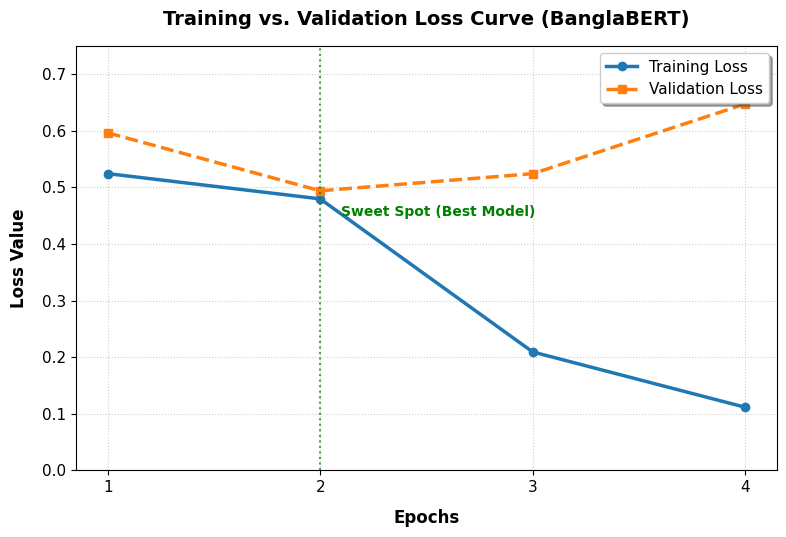

সফলভাবে 'loss_curve.png' সেভ হয়েছে!


In [22]:
import matplotlib.pyplot as plt

# তোমার দেওয়া আসল রেজাল্টের ডেটা
epochs = [1, 2, 3, 4]
training_loss = [0.524245, 0.479645, 0.209265, 0.111559]
validation_loss = [0.596342, 0.493932, 0.524156, 0.647307]

# গ্রাফের সাইজ এবং স্টাইল সেট করা
plt.figure(figsize=(8, 5.5))
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

# ট্রেইনিং এবং ভ্যালিডেশন লসের লাইন প্লট করা
plt.plot(epochs, training_loss, color='#1f77b4', marker='o', linewidth=2.5, label='Training Loss')
plt.plot(epochs, validation_loss, color='#ff7f0e', marker='s', linewidth=2.5, linestyle='--', label='Validation Loss')

# সুইট স্পট (Epoch 2) এবং ওভারফিটিং জোন (Epoch 4) নির্দেশ করা
plt.axvline(x=2, color='green', linestyle=':', alpha=0.7, linewidth=1.5)
plt.text(2.1, 0.45, 'Sweet Spot (Best Model)', color='green', fontweight='bold', fontsize=10)

# plt.annotate('Overfitting Starts Here', xy=(3, 0.524), xytext=(2.5, 0.58),
#              arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
#              fontweight='bold', color='red', fontsize=10)

# এক্সিস লেবেল এবং টাইটেল সেট করা
plt.title('Training vs. Validation Loss Curve (BanglaBERT)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Loss Value', fontsize=12, fontweight='bold', labelpad=10)

# এক্সিসের লিমিট ও গ্রিড ঠিক করা
plt.xticks(epochs)
plt.ylim(0.0, 0.75)
plt.grid(True, linestyle=':', alpha=0.6)

# লেজেন্ড বা সূচক পজিশন
plt.legend(loc='upper right', frameon=True, shadow=True, facecolor='white')

# হাই-রেজোলিউশনে ছবি সেভ করা (DPI=300 পেপারের জন্য স্ট্যান্ডার্ড)
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print("সফলভাবে 'loss_curve.png' সেভ হয়েছে!")

ভ্যালিডেশন সেটের প্রেডিকশন বের করা হচ্ছে...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


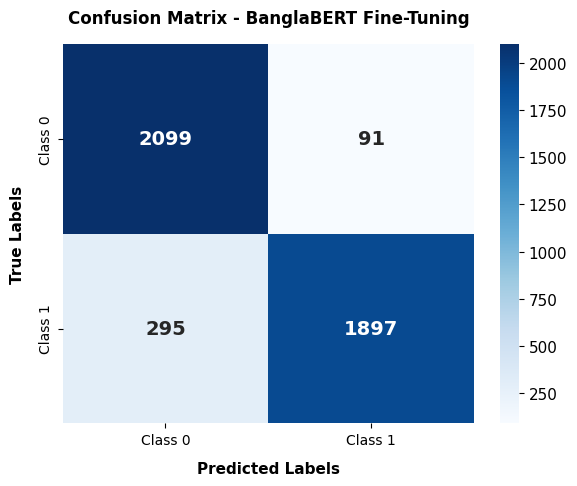

সফলভাবে 'confusion_matrix.png' সেভ হয়েছে!


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ১. ভ্যালিডেশন সেট (X_test) এর ওপর মডেলের প্রেডিকশন বের করা
print("ভ্যালিডেশন সেটের প্রেডিকশন বের করা হচ্ছে...")
predictions = trainer.predict(val_dataset)
preds_labels = np.argmax(predictions.predictions, axis=-1)

# ২. আসল লেবেল (y_test) এবং প্রেডিকশনের তুলনা করে কনফিউশন ম্যাট্রিক্স তৈরি
cm = confusion_matrix(y_test, preds_labels)

# ৩. সুন্দর এবং প্রফেশনাল প্লট তৈরি করা
plt.figure(figsize=(6, 5))
# তোমার পেপারের থিম অনুযায়ী ব্লু (Blues) কালারম্যাপ ব্যবহার করা হয়েছে
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Class 0', 'Class 1'], 
            yticklabels=['Class 0', 'Class 1'],
            annot_kws={"size": 14, "weight": "bold"})

# লেবেল এবং টাইটেল সেট করা (সব প্রফেশনাল পেপারের স্টাইল অনুযায়ী)
plt.title('Confusion Matrix - BanglaBERT Fine-Tuning', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Predicted Labels', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('True Labels', fontsize=11, fontweight='bold', labelpad=10)

# এক্সিস ঠিক করা
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# হাই-রেজোলিউশনে (300 DPI) ছবি সেভ করা
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("সফলভাবে 'confusion_matrix.png' সেভ হয়েছে!")

ROC Curve তৈরির জন্য মডেলের প্রবাবিলিটি (Probabilities) হিসাব করা হচ্ছে...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


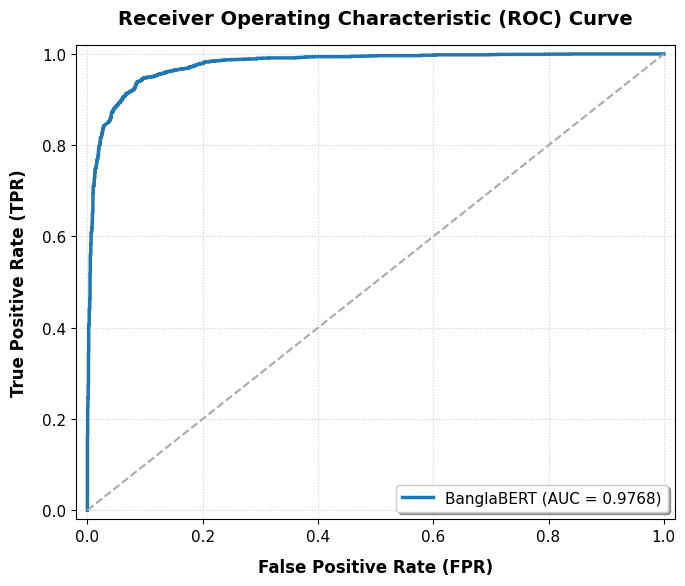

সফলভাবে 'roc_curve.png' সেভ হয়েছে! এর AUC স্কোর এসেছে: 0.9768


In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import torch.nn.functional as F
import torch
import numpy as np

print("ROC Curve তৈরির জন্য মডেলের প্রবাবিলিটি (Probabilities) হিসাব করা হচ্ছে...")

# ১. মডেলের লজিটস (Logits) প্রেডিক্ট করা
predictions = trainer.predict(val_dataset)
logits = torch.tensor(predictions.predictions)

# ২. Softmax ব্যবহার করে লজিটসকে প্রবাবিলিটিতে (Probability) রূপান্তর করা
probabilities = F.softmax(logits, dim=-1).numpy()

# আমরা Class 1 (Positive Class) এর প্রবাবিলিটি নেব
y_probs = probabilities[:, 1]

# ৩. False Positive Rate (FPR) এবং True Positive Rate (TPR) হিসাব করা
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

# ৪. প্রফেশনাল পেপার স্টাইলে প্লট তৈরি করা
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'BanglaBERT (AUC = {roc_auc:.4f})')

# ডিফল্ট র্যান্ডম ক্লাসিফায়ার লাইন (ড্যাশড লাইন)
plt.plot([0, 1], [0, 1], color='darkgray', lw=1.5, linestyle='--')

# এক্সিস এবং গ্রিড স্টাইলিং
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold', pad=15)

# গ্রিড ও লেজেন্ড যোগ করা
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="lower right", frameon=True, shadow=True, facecolor='white', fontsize=11)

# হাই-রেজোলিউশনে (300 DPI) ছবি সেভ করা
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"সফলভাবে 'roc_curve.png' সেভ হয়েছে! এর AUC স্কোর এসেছে: {roc_auc:.4f}")

In [36]:
import re
import pandas as pd
import numpy as np
import emoji 
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_curve, auc

print("=== ১. নতুন ডাটাসেট লোড ও প্রিপারেশন ===")
df_new = pd.read_csv('https://github.com/Apur52027/Dataset_ML/blob/main/Dataset%203.csv?raw=true')
df_new['label_num'] = df_new['Label'].map({'depressive': 1, 'non_depressive': 0})
df_new = df_new.dropna(subset=['Text', 'label_num'])

texts_new = df_new['Text'].astype(str).values
labels_new = df_new['label_num'].values.astype(int)

=== ১. নতুন ডাটাসেট লোড ও প্রিপারেশন ===


In [37]:
# টেক্সট ক্লিনিং ফাংশন
def clean_bengali_text(text):
    text = emoji.replace_emoji(text, replace='')
    text = re.sub(r'http\S+|www\S+|@\S+', '', text)
    text = re.sub(r'[^\u0980-\u09FF\s।]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

texts_clean = [clean_bengali_text(t) for t in texts_new]

print("=== ২. নতুন ডাটাসেটকে ৮০:২০ অনুপাতে স্প্লিট করা ===")
# stratify=labels_new ব্যবহার করায় ক্লাস ব্যালেন্স ঠিক থাকবে
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    texts_clean, labels_new, test_size=0.2, random_state=42, stratify=labels_new
)

print(f"New training sample: {len(y_train_new)} | New test sample: {len(y_test_new)}")


=== ২. নতুন ডাটাসেটকে ৮০:২০ অনুপাতে স্প্লিট করা ===
New training sample: 7500 | New test sample: 1876


In [39]:
print("=== ৪. ট্রেইনড মডেল মেমরি থেকে সংগ্রহ ও ফাইন-টিউনিং কনফিগারেশন ===")
# তোমার আগের ট্রেইনার থেকে সেরা ওয়েট সম্বলিত মডেলটি নেওয়া হচ্ছে
adapted_model = trainer.model 

# নতুন ডোমেনের জন্য কম লার্নিং রেটে অল্প Epoch-এর আর্গুমেন্ট (যাতে আগের শেখা জ্ঞান ভুলে না যায়)
adaptation_args = TrainingArguments(
    output_dir="./results_adapted",
    num_train_epochs=3,                 # ৩টি Epoch নতুন ডোমেন চেনার জন্য যথেষ্ট
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,                 # একটু কম লার্নিং রেট (Safe Fine-tuning)
    weight_decay=0.05,
    logging_dir="./logs_adapted",
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    greater_is_better=False
)

# নতুন ডোমেন ট্রেইনার
adaptation_trainer = Trainer(
    model=adapted_model,
    args=adaptation_args,
    train_dataset=train_dataset_new,
    eval_dataset=test_dataset_new,
    compute_metrics=compute_metrics, # তোমার আগের কোডের ফাংশনটিই ব্যবহৃত হবে
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


=== ৪. ট্রেইনড মডেল মেমরি থেকে সংগ্রহ ও ফাইন-টিউনিং কনফিগারেশন ===


In [40]:
print("=== ৫. ডোমেন অ্যাডাপ্টেশন (Transfer Learning) শুরু হচ্ছে ===")
adaptation_trainer.train()

=== ৫. ডোমেন অ্যাডাপ্টেশন (Transfer Learning) শুরু হচ্ছে ===


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.812544,0.736962,0.829957,0.839456
2,0.543775,0.672700,0.867271,0.868740
3,0.386229,0.716450,0.873667,0.874137


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=705, training_loss=0.6279374137837836, metrics={'train_runtime': 627.0946, 'train_samples_per_second': 35.88, 'train_steps_per_second': 1.124, 'total_flos': 2959999372800000.0, 'train_loss': 0.6279374137837836, 'epoch': 3.0})

In [41]:
print("=== ৬. নতুন টেস্ট সেটের ওপর চূড়ান্ত ইভালুয়েশন ===")
eval_results_new = adaptation_trainer.evaluate()

print("\n" + "="*45)
print(f"🎯 ADAPTED MODEL PERFORMANCE ON DATASET 3:")
print(f"Adapted Test Accuracy: {eval_results_new['eval_accuracy']:.4f} ({eval_results_new['eval_accuracy']*100:.2f}%)")
print(f"Adapted Test F1-Score: {eval_results_new['eval_f1']:.4f} ({eval_results_new['eval_f1']*100:.2f}%)")
print("="*45 + "\n")


=== ৬. নতুন টেস্ট সেটের ওপর চূড়ান্ত ইভালুয়েশন ===


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



🎯 ADAPTED MODEL PERFORMANCE ON DATASET 3:
Adapted Test Accuracy: 0.8673 (86.73%)
Adapted Test F1-Score: 0.8687 (86.87%)



=== ৭. আপডেটেড ভিজ্যুয়ালাইজেশন সেভ করা ===


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


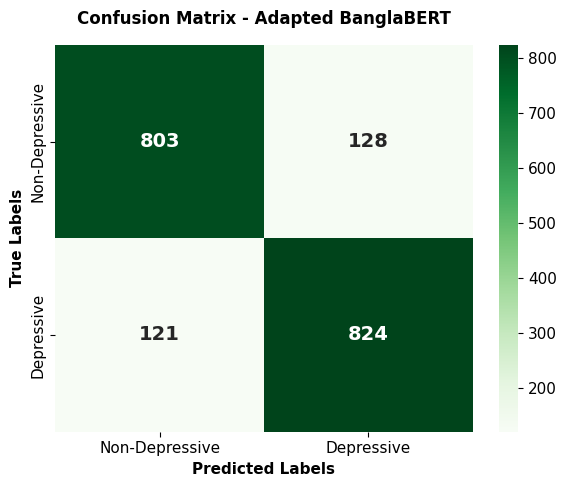

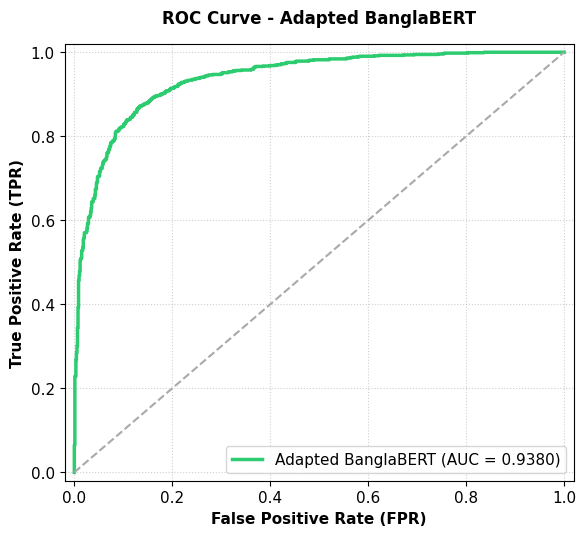

🎉 নতুন ডোমেনের সব গ্রাফ এবং হাই-পারফর্মিং রেজাল্ট সেভ হয়েছে!


In [42]:
print("=== ৭. আপডেটেড ভিজ্যুয়ালাইজেশন সেভ করা ===")

# ১. কনফিউশন ম্যাট্রিক্স
predictions = adaptation_trainer.predict(test_dataset_new)
preds_labels = np.argmax(predictions.predictions, axis=-1)
cm = confusion_matrix(y_test_new, preds_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=True,
            xticklabels=['Non-Depressive', 'Depressive'], 
            yticklabels=['Non-Depressive', 'Depressive'],
            annot_kws={"size": 14, "weight": "bold"})
plt.title('Confusion Matrix - Adapted BanglaBERT', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Predicted Labels', fontsize=11, fontweight='bold')
plt.ylabel('True Labels', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('adapted_confusion_matrix.png', dpi=300)
plt.show()

# ২. ROC Curve
logits_tensor = torch.tensor(predictions.predictions)
probabilities = F.softmax(logits_tensor, dim=-1).numpy()
y_probs = probabilities[:, 1]

fpr, tpr, _ = roc_curve(y_test_new, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5.5))
plt.plot(fpr, tpr, color='#2ecc71', lw=2.5, label=f'Adapted BanglaBERT (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='darkgray', lw=1.5, linestyle='--')
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (TPR)', fontsize=11, fontweight='bold')
plt.title('ROC Curve - Adapted BanglaBERT', fontsize=12, fontweight='bold', pad=15)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="lower right", frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('adapted_roc_curve.png', dpi=300)
plt.show()

print("🎉 নতুন ডোমেনের সব গ্রাফ এবং হাই-পারফর্মিং রেজাল্ট সেভ হয়েছে!")